In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import preprocessing as pp
import model_training as mt
import implementations as imp
import cross_validation as cv
from helpers import load_csv_data

## Data loading and exploration

Training samples  (N_train): 328135
Features          (D)      : 321
Classes: [-1, 1] | Counts: [299160, 28975]
Test samples      (N_test) : 109379


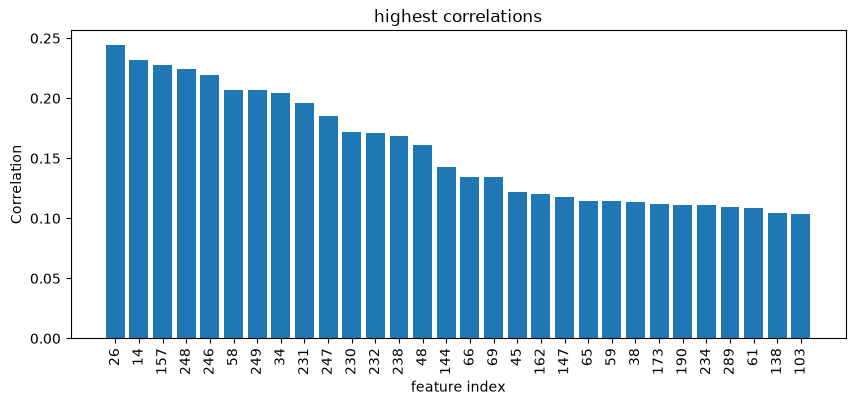

In [2]:
x_train, x_test, y_train, train_ids, test_ids = load_csv_data("data/")
N, D = pp.explore_dimensions(y_train, x_train, x_test)
pp.most_correlated_features(x_train, y_train)

## preprocessing

In [3]:
tx_train, tx_test = pp.preprocess(x_train, x_test)

#### convert {-1, 1} in {0, 1}

In [ ]:
y01 = mt.to_01(y_train)
print(f"% positives: {100 * y01.mean():.2f}")  #pourcentage de malade ? 


% positives: 8.83


## model comparison and best threshold finding

In [ ]:
results = mt.run_baselines(y01, tx_train)

majority | thr=0.5: acc=0.9117 f1=0.0000 | best thr=0.0000: f1=0.1623 prec=0.0883 rec=1.0000 acc=0.0883
least_squares | thr=0.5: acc=0.9119 f1=0.0090 | best thr=0.2150: f1=0.4079 prec=0.3273 rec=0.5411 acc=0.8613
ridge lambda=1e-06 | thr=0.5: acc=0.9119 f1=0.0090 | best thr=0.2151: f1=0.4078 prec=0.3273 rec=0.5410 acc=0.8613
ridge lambda=1e-05 | thr=0.5: acc=0.9119 f1=0.0091 | best thr=0.2162: f1=0.4078 prec=0.3287 rec=0.5372 acc=0.8622
ridge lambda=1e-04 | thr=0.5: acc=0.9119 f1=0.0089 | best thr=0.2162: f1=0.4077 prec=0.3287 rec=0.5369 acc=0.8623
ridge lambda=1e-03 | thr=0.5: acc=0.9119 f1=0.0086 | best thr=0.2153: f1=0.4081 prec=0.3284 rec=0.5387 acc=0.8620
ridge lambda=1e-02 | thr=0.5: acc=0.9118 f1=0.0050 | best thr=0.2104: f1=0.4075 prec=0.3258 rec=0.5437 acc=0.8604
ridge lambda=1e-01 | thr=0.5: acc=0.9117 f1=0.0001 | best thr=0.1903: f1=0.4042 prec=0.3237 rec=0.5380 acc=0.8599
ridge lambda=1e+00 | thr=0.5: acc=0.9117 f1=0.0000 | best thr=0.1222: f1=0.3963 prec=0.3235 rec=0.5113 

Graph saved as : baselines_comparison.png


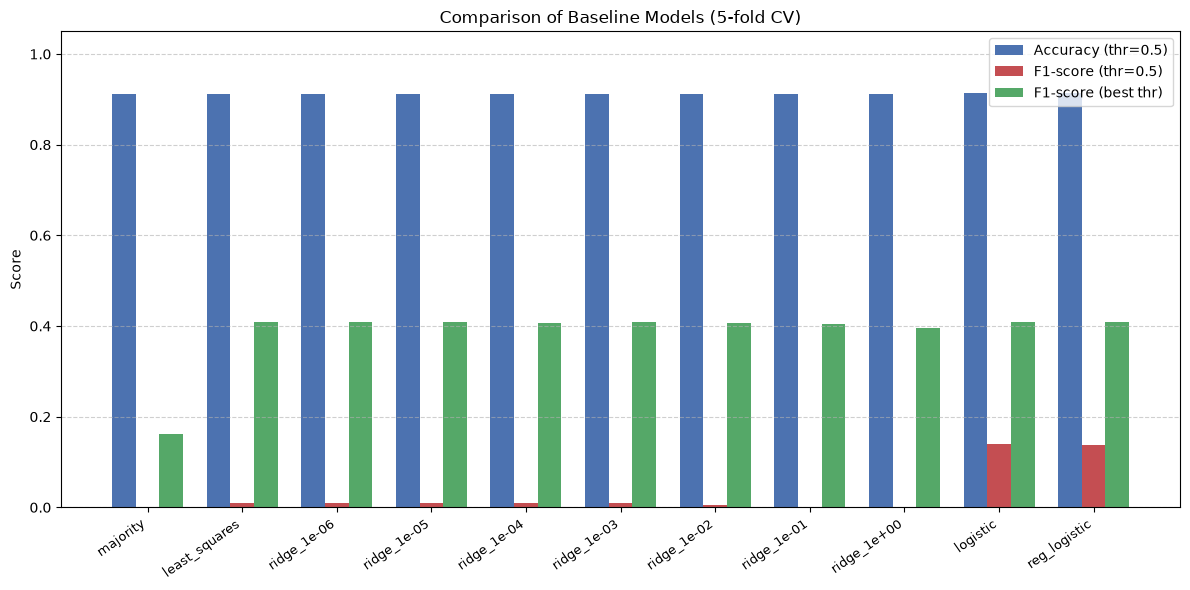

In [ ]:
mt.plot_baselines_summary(results)

The best model is the regularized logistic regression.

## hyperparameters finding

In [ ]:
best_cfg, _ = mt.grid_search_weighted_logistic(y01, tx_train)

wlogistic lambda=1e-06 gamma=0.1 pos_w=1.0 | thr=0.5: acc=0.9130 f1=0.1403 | best thr=0.2109: f1=0.4078 prec=0.3240 rec=0.5502 acc=0.8589
wlogistic lambda=1e-06 gamma=0.1 pos_w=3.0 | thr=0.5: acc=0.8837 f1=0.3940 | best thr=0.4049: f1=0.4074 prec=0.3152 rec=0.5757 acc=0.8521
wlogistic lambda=1e-06 gamma=0.1 pos_w=8.0 | thr=0.5: acc=0.7832 f1=0.3775 | best thr=0.6392: f1=0.4068 prec=0.3137 rec=0.5783 acc=0.8511
wlogistic lambda=1e-06 gamma=0.3 pos_w=1.0 | thr=0.5: acc=0.9138 f1=0.1883 | best thr=0.1834: f1=0.4089 prec=0.3191 rec=0.5691 acc=0.8547
wlogistic lambda=1e-06 gamma=0.3 pos_w=3.0 | thr=0.5: acc=0.8848 f1=0.3973 | best thr=0.3937: f1=0.4087 prec=0.3159 rec=0.5789 acc=0.8521
wlogistic lambda=1e-06 gamma=0.3 pos_w=8.0 | thr=0.5: acc=0.7890 f1=0.3809 | best thr=0.6436: f1=0.4068 prec=0.3167 rec=0.5687 acc=0.8536
wlogistic lambda=1e-05 gamma=0.1 pos_w=1.0 | thr=0.5: acc=0.9130 f1=0.1400 | best thr=0.2109: f1=0.4078 prec=0.3240 rec=0.5502 acc=0.8589
wlogistic lambda=1e-05 gamma=0.1 p

In [15]:
print (best_cfg)

{'lambda_': np.float64(0.001), 'gamma': 0.3, 'pos_weight': 1.0, 'max_iters': 300}
